# MicroCT step 1b — preprocess the frames

Streams scan 94 (121 frames, weak CA + strong CA + the SAMPLE, strong CA
moving, sample fixed) through the same chain this folder's `step0a_convert`
uses, and writes `/exchange/pdata`.

```
dark_subtract_clip -> fill_dead -> remove_outliers -> flat_field_divide
```

`pdata` is **INTENSITY**. `RecHoloCoded.F0` compares `K|psi|^2` against it and
the amplitude model takes its own square root, so nothing is square-rooted
here.

Also (re)computes `/exchange/pref` from scan 92 (weak CA alone, no sample) --
the same convention this folder's `step0a_convert` uses for the NFP's `pref`.
Recomputed independently here, at this stage's own crop, rather than copied
from `nfp/data_nfp.h5`, so the two stages never silently drift apart.

No angle subsampling concept here at all -- `nframes=121` is the whole scan.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../../src'))
import numpy as np, cupy as cp, h5py
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def cbshow(ax, img, title, cmap='gray', **kw):
    im = ax.imshow(np.asarray(img), cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.05)
    ax.figure.colorbar(im, cax=cax)

print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Config

In [2]:
# --- everything comes from config_step6.conf. Edit THAT file, not this cell.
from holotomocupy.config import parse_args_holo_coded
CFG = parse_args_holo_coded('config_step6.conf')

RAW_DIR = '/data3/cekmekci/microCT_nano_holo'   # raw_dir; parse_args_holo_coded has no key for it
OUT_H5  = CFG.in_file

DARK_H5   = f'{RAW_DIR}/scan-0090_orca.h5'   # dark
FLAT_H5   = f'{RAW_DIR}/scan-0091_orca.h5'   # flat: NO CA at all
WEAKCA_H5 = f'{RAW_DIR}/scan-0092_orca.h5'   # weak CA alone, no sample -> pref
GRID_H5   = f'{RAW_DIR}/scan-0094_orca.h5'   # weak + strong CA + SAMPLE (fixed), 121 frames
ORCA      = '/entry/instrument/orca/data'

ENERGY  = CFG.energy if CFG.energy is not None else 19.90
Z1      = CFG.z1                 # focus -> SAMPLE (TODO CONFIRM, see config comment)
Z_CODE  = CFG.z1_code            # focus -> weak/strong CA plane
Z_DET   = CFG.focusdetectordistance
DET_PIX = CFG.detector_pixelsize # UNBINNED
nz, n   = CFG.crop_nz, CFG.crop_n   # NATIVE crop resolution -- NOT CFG.nz/CFG.n,
                                    # which are the solve's own BINNED grid.
                                    # Steps 1a-1c never bin anything; that is
                                    # HoloCodedReader's job alone at solve time.
CROP = (nz, n)
DEZINGER = (3, 0.8)
NFRAMES = CFG.nframes   # ALL 121 frames of scan 94 -- no subsampling anywhere

print(f'{ENERGY} keV   z1(sample) {Z1} m   z1_code(CA plane) {Z_CODE} m   z_det {Z_DET} m')
print(f'crop {CROP}, native resolution -- the solve bins to {CFG.nz} x {CFG.n} at bin={CFG.bin}')
assert Z_CODE < Z1, 'the CA plane must be BEFORE the sample for RecHoloCoded'

19.9 keV   z1(sample) 0.14925 m   z1_code(CA plane) 0.14125 m   z_det 0.74625 m
crop (2048, 2048), native resolution -- the solve bins to 512 x 512 at bin=2


## Preprocessing helpers

In [3]:
# Ports of phascade.preprocess.{dark_subtract_clip, fill_dead, remove_outliers,
# flat_field_divide}. Identical to this folder's own step0a_convert -- same
# detector, same chain. Stages 0 and 1 MUST preprocess the same way, or the
# warm start from stage 0 does not line up with the data here.
from cupyx.scipy.ndimage import median_filter

def dark_subtract_clip(data, dark_mean):
    out = np.asarray(data, 'float32') - dark_mean[np.newaxis]
    np.clip(out, 0, None, out=out)
    return out

def _runs(idx):
    return [] if len(idx) == 0 else np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)

def fill_dead(data, mask):
    out = np.array(data, copy=True)
    ny, nx = mask.shape
    for g in _runs(np.where(mask.mean(1) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < ny
        for r in g:
            if hl and hh:
                w = (r - lo) / (hi - lo)
                out[..., r, :] = (1 - w) * out[..., lo, :] + w * out[..., hi, :]
            elif hl:
                out[..., r, :] = out[..., lo, :]
            elif hh:
                out[..., r, :] = out[..., hi, :]
    for g in _runs(np.where(mask.mean(0) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < nx
        for c in g:
            if hl and hh:
                w = (c - lo) / (hi - lo)
                out[..., :, c] = (1 - w) * out[..., :, lo] + w * out[..., :, hi]
            elif hl:
                out[..., :, c] = out[..., :, lo]
            elif hh:
                out[..., :, c] = out[..., :, hi]
    return out

def remove_outliers(data, radius=3, threshold=0.8):
    # window is radius x radius, NOT 2*radius+1 -- matches phascade
    res = np.asarray(data, 'float32').copy()
    for k in range(res.shape[0]):
        f = cp.asarray(res[k])
        med = median_filter(f, [radius, radius])
        res[k] = cp.asnumpy(cp.where(cp.abs(f - med) > med * threshold, med, f))
    return res

def flat_field_divide(frames, flat_mean):
    fmean = float(np.asarray(flat_mean).mean()) + 1e-12
    return np.nan_to_num(np.asarray(frames, 'float32') / fmean, nan=1.0)

def bin2(a, nbin):
    for _ in range(nbin):
        a = 0.5 * (a[..., 0::2, :] + a[..., 1::2, :])
        a = 0.5 * (a[..., :, 0::2] + a[..., :, 1::2])
    return a

## Geometry

In [4]:
with h5py.File(GRID_H5, 'r') as f:
    NANG, NY, NX = f[ORCA].shape
assert NANG == NFRAMES, f'{GRID_H5} has {NANG} frames, config says nframes={NFRAMES}'
cy, cx = NY // 2, NX // 2
SL = (slice(cy - CROP[0] // 2, cy + CROP[0] // 2),
      slice(cx - CROP[1] // 2, cx + CROP[1] // 2))

mag       = Z_DET / Z1
voxelsize = DET_PIX / mag   # NATIVE voxel size -- no bin factor, steps 1a-1c never bin

print(f'orca {NY} x {NX}, {NANG} frames; crop rows {SL[0].start}:{SL[0].stop} '
      f'cols {SL[1].start}:{SL[1].stop}')
print(f'voxel {voxelsize*1e9:.2f} nm   magnification {mag:.3f}')

orca 2592 x 4608, 121 frames; crop rows 272:2320 cols 1280:3328
voxel 46.00 nm   magnification 5.000


## The probe reference: scan 92 (weak CA alone)

In [5]:
with h5py.File(OUT_H5, 'r') as f:
    dark      = np.asarray(f['/exchange/dark'], 'float32')
    flat_norm = np.asarray(f['/exchange/flat_norm'], 'float32')
    dead_mask = np.asarray(f['/exchange/dead_mask']).astype(bool)
    flat_mean = float(f['/exchange/flat_mean'][0])

WEAKCA_H5 = f'{RAW_DIR}/scan-0092_orca.h5'
with h5py.File(WEAKCA_H5, 'r') as f:
    NWEAK = f[ORCA].shape[0]
    pref_raw = np.empty((NWEAK, nz, n), 'float32')
    CHUNK = 8
    for cs in range(0, NWEAK, CHUNK):
        ce = min(cs + CHUNK, NWEAK)
        raw = np.asarray(f[ORCA][cs:ce, SL[0], SL[1]], 'float32')
        raw = dark_subtract_clip(raw, dark)
        raw = fill_dead(raw, dead_mask)
        raw = remove_outliers(raw, 3, 0.8)
        raw = flat_field_divide(raw, flat_mean)
        pref_raw[cs:ce] = raw
pref = pref_raw.mean(0)
del pref_raw

with h5py.File(OUT_H5, 'a') as f:
    if '/exchange/pref' in f:
        del f['/exchange/pref']
    f.create_dataset('/exchange/pref', data=pref)
print(f'pref (beam x weak CA, scan 92 mean of {NWEAK} frames): {pref.shape} -> /exchange/pref')

pref (beam x weak CA, scan 92 mean of 100 frames): (2048, 2048) -> /exchange/pref


## Stream the projections

`pdata` goes in UNBINNED, at the native crop size, for ALL 121 frames --
`HoloCodedReader.read_data` bins it by `2**bin` on the way out, so pre-binning
here would bin it twice.

In [6]:
CY, CX = CROP
CHUNK = 8
with h5py.File(OUT_H5, 'a') as fo:
    if '/exchange/pdata' in fo:
        del fo['/exchange/pdata']
    ds = fo.create_dataset('/exchange/pdata', shape=(NFRAMES, CY, CX),
                           dtype='float32', chunks=(1, CY, CX))
    with h5py.File(GRID_H5, 'r') as fi:
        for cs in range(0, NFRAMES, CHUNK):
            ce = min(cs + CHUNK, NFRAMES)
            raw = np.asarray(fi[ORCA][cs:ce, SL[0], SL[1]], 'float32')
            raw = dark_subtract_clip(raw, dark)
            raw = fill_dead(raw, dead_mask)
            raw = remove_outliers(raw, 3, 0.8)
            ds[cs:ce] = flat_field_divide(raw, flat_mean)
            print(f'  {ce}/{NFRAMES}', flush=True)
gb = NFRAMES * CY * CX * 4 / 1024 ** 3
print(f'wrote /exchange/pdata {(NFRAMES, CY, CX)} UNBINNED  ({gb:.2f} GB)')
print(f'   the solve will bin it by 2**{CFG.bin} -> {CFG.nz} x {CFG.n}')

  8/121
  16/121
  24/121
  32/121
  40/121
  48/121
  56/121
  64/121
  72/121
  80/121
  88/121
  96/121
  104/121
  112/121
  120/121
  121/121
wrote /exchange/pdata (121, 2048, 2048) UNBINNED  (1.89 GB)
   the solve will bin it by 2**2 -> 512 x 512


## Diagnostic: does the strong-CA speckle show up, and is the sample fixed?

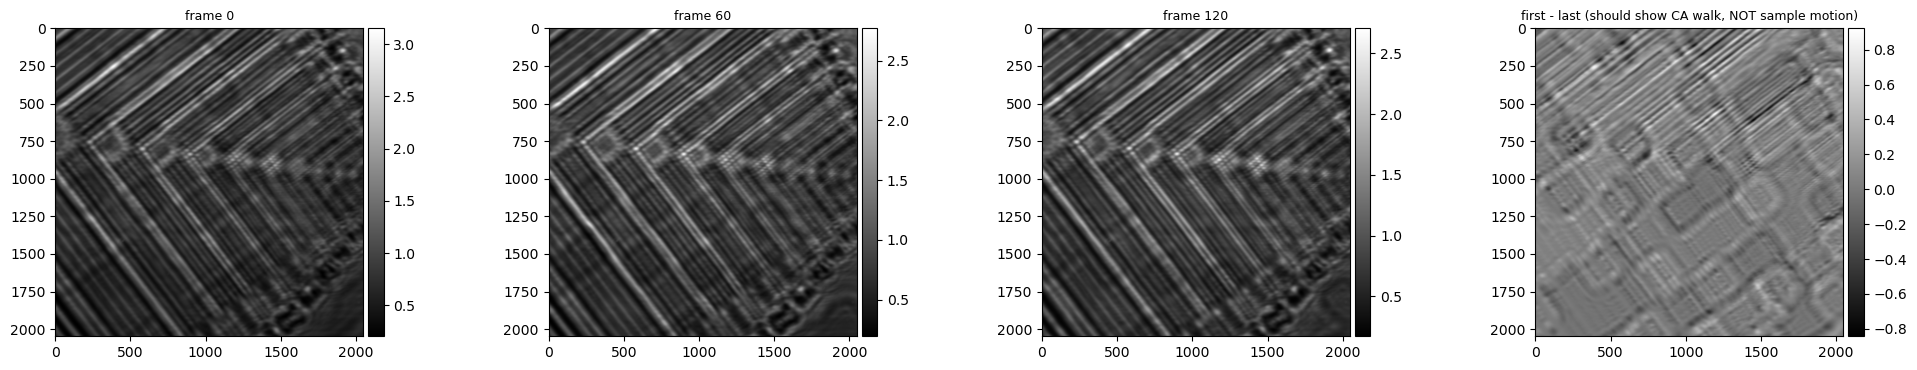

In [7]:
with h5py.File(OUT_H5, 'r') as f:
    p0 = f['/exchange/pdata'][0]
    pm = f['/exchange/pdata'][NFRAMES // 2]
    pl = f['/exchange/pdata'][NFRAMES - 1]
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
cbshow(ax[0], p0, 'frame 0')
cbshow(ax[1], pm, f'frame {NFRAMES//2}')
cbshow(ax[2], pl, f'frame {NFRAMES-1}')
cbshow(ax[3], p0 - pl, 'first - last (should show CA walk, NOT sample motion)')
plt.tight_layout(); plt.show()